In [14]:
import os
print(os.getcwd())

/Users/hedanni/Desktop/DEPA_downstream


In [15]:
# Cell 1: 加载autoreload机制 + 所有需要的库
%load_ext autoreload
%autoreload 2

import yaml
from pathlib import Path
from depa_downstream import (
    load_cnmf_outputs,
    compute_program_direction, plot_program_direction_summary,
    compute_leading_genes,
    compute_foreground_gene_directions, plot_leading_genes_bar,
    compute_usage_binned_wpsi,subset_data_to_celltype,plot_usage_binned_trend,
    compute_contrast_association, plot_association_heatmap, plot_program_umap_grid,
    compute_gene_celltype_wpsi, plot_gene_celltype_heatmap,
    compute_program_gene_sets, select_program_markers,
    run_enrichment, plot_enrichment_bubble,
    extract_enrichment_driver_genes, plot_driver_gene_heatmap,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [16]:
# Cell 2: 读CONFIG
PROJECT_ROOT = Path.cwd()
CONFIG = yaml.safe_load(open(PROJECT_ROOT / "configs" / "covid19.yaml"))

In [17]:
import os

PATH_KEYS = [
    "cnmf_dir", "h5ad_path", "feature_anno_path",
    "wpsi_matrix_path", "psi_matrix_path",
    "depa_feature_source_path", "gene_symbol_map_path",
    "output_root",
]

def resolve_paths(config: dict) -> dict:
    root = os.path.expanduser(config["root_dir"])
    for key in PATH_KEYS:
        val = config.get(key)
        if not val:                      # 可选项没填就跳过
            continue
        if not os.path.isabs(val):       # 已经是绝对路径的保持不变
            resolved = os.path.join(root, val)
            if val.endswith("/"):        # 保留末尾斜杠
                resolved = resolved.rstrip("/") + "/"
            config[key] = resolved
    return config

CONFIG = resolve_paths(CONFIG)

In [37]:
# Cell 3: 读数据（这一步比较慢，几十秒到1分钟左右，因为要读wpsi/psi这种几个GB的大矩阵）
data = load_cnmf_outputs(CONFIG)

检查 cNMF 输入文件...
  [OK] spectra_score: data/covid_19_data/cnmf_output_identity_state/COVID_DEAPA_programs/COVID_DEAPA_programs.gene_spectra_score.k_6.dt_0_01.txt (0.2 MB)
  [OK] spectra_tpm: data/covid_19_data/cnmf_output_identity_state/COVID_DEAPA_programs/COVID_DEAPA_programs.gene_spectra_tpm.k_6.dt_0_01.txt (0.1 MB)
  [OK] usage: data/covid_19_data/cnmf_output_identity_state/COVID_DEAPA_programs/COVID_DEAPA_programs.usages.k_6.dt_0_01.consensus.txt (3.4 MB)

读取 cNMF spectra 与 usage...
  spectra: (6, 1231)  (programs x PACs)
  usage:   (42253, 6)  (cells x programs)
  programs (已统一命名): ['P01', 'P02', 'P03', 'P04', 'P05', 'P06']

计算 spectra 逐 program 的 Z-score...
  spectra_z: (6, 1231)

读取 metadata (h5ad .obs)...
  meta: (42253, 8)  (cells x columns)
  sample     -> 列 'sample'，取值样例: ['cov_01', 'cov_04', 'cov_10', 'cov_11', 'Healthy_07']
  celltype   -> 列 'cell_type'，取值样例: ['Plasma', 'NK', 'Naive_B', 'cDC2', 'HSPC']
  umap1      -> 列 'UMAP_1'，取值样例: [-0.0625057098623196, -5.4736776379104

In [19]:
# Cell 4: Layer1
program_direction = compute_program_direction(data, CONFIG)
leading_genes = compute_leading_genes(data, CONFIG, program_direction)
program_direction[["n_fg_genes", "n_bg_genes", "bg_median", "delta_median", "pval", "padj", "direction"]]


计算基因级 wPSI（8793 个基因 x 42253 个细胞）...
  基因检出率过滤(min_detection_rate=0.1): 排除 2788/8793 个基因(wPSI在多数细胞中卡在0/1边界，中位数不可靠)
  过滤后有效基因数: 6005
  cNMF分析涉及的基因全集（pac_universe，基于1231个PAC）大小: 600
  background_scope = 'pac_universe'
  [P01] 前景基因=59, 背景基因=541, delta_median=-0.1267, pval=1.75e-01 -> Proximal
  [P02] 前景基因=62, 背景基因=538, delta_median=+0.0237, pval=6.93e-01 -> Distal
  [P03] 前景基因=46, 背景基因=554, delta_median=+0.0094, pval=8.48e-01 -> Distal
  [P04] 前景基因=58, 背景基因=542, delta_median=-0.1046, pval=1.87e-02 -> Proximal
  [P05] 前景基因=31, 背景基因=569, delta_median=+0.0652, pval=3.38e-01 -> Distal
  [P06] 前景基因=37, 背景基因=563, delta_median=+0.2176, pval=1.31e-01 -> Distal

共 6/6 个 program 完成方向检验
  基因检出率过滤(min_detection_rate=0.1): 排除 2788/8793 个基因(wPSI在多数细胞中卡在0/1边界，中位数不可靠)
  过滤后有效基因数: 6005
  [P01] direction=Proximal, leading genes: ['RAN', 'RPL34', 'OPTN', 'PIK3IP1', 'CD247']...
  [P02] direction=Distal, leading genes: ['ENSG00000268173.3', 'APOBEC3A', 'TRIB1', 'DOK3', 'LRRC25']...
  [P03] direction=Distal, le

,n_fg_genes,n_bg_genes,bg_median,delta_median,pval,padj,direction
program,,,,,,,
P01,59,541,0.255516,-0.126662,0.175065,0.350130,Proximal
P02,62,538,0.232913,0.023693,0.693164,0.831797,Distal
P03,46,554,0.237397,0.009394,0.848233,0.848233,Distal
P04,58,542,0.256468,-0.104642,0.018730,0.112379,Proximal
P05,31,569,0.234955,0.065154,0.338376,0.507564,Distal
P06,37,563,0.225885,0.217642,0.130640,0.350130,Distal


In [20]:
gene_tables, consistency_summary = compute_foreground_gene_directions(data, CONFIG, program_direction)
consistency_summary

# 挑一致性最强的program画出全部前景基因的方向分布（复用已有的plot_leading_genes_bar，
# 之前只用leading_genes传了top_n个基因，这里传全部前景基因，直接看整体分布）
for p in ["P06", "P04"]:
    plot_leading_genes_bar(gene_tables, p, CONFIG["output_root"] + "layer1",
                            direction_label=program_direction.loc[p, "direction"])

  基因检出率过滤(min_detection_rate=0.1): 排除 2788/8793 个基因(wPSI在多数细胞中卡在0/1边界，中位数不可靠)
  过滤后有效基因数: 6005
  [P01] 前景基因59个(非零59个): 与program方向(Proximal)一致 36/59 (61.0%), 符号检验 p=0.059
  [P02] 前景基因62个(非零62个): 与program方向(Distal)一致 34/62 (54.8%), 符号检验 p=0.263
  [P03] 前景基因46个(非零46个): 与program方向(Distal)一致 24/46 (52.2%), 符号检验 p=0.441
  [P04] 前景基因58个(非零58个): 与program方向(Proximal)一致 36/58 (62.1%), 符号检验 p=0.043
  [P05] 前景基因31个(非零31个): 与program方向(Distal)一致 17/31 (54.8%), 符号检验 p=0.360
  [P06] 前景基因37个(非零37个): 与program方向(Distal)一致 24/37 (64.9%), 符号检验 p=0.049
  已保存: /Users/hedanni/Desktop/DEPA_downstream/outputs/covid_19/layer1/layer1_leading_genes_P06.png
  已保存: /Users/hedanni/Desktop/DEPA_downstream/outputs/covid_19/layer1/layer1_leading_genes_P04.png


In [21]:
data_plasma = subset_data_to_celltype(data, CONFIG, "Plasma", min_cells=50)

if data_plasma is not None:
    # 1. pooled方向检验，限定Plasma内部
    program_direction_plasma = compute_program_direction(data_plasma, CONFIG)
    print(program_direction_plasma.loc[["P06"]][["n_fg_genes", "n_bg_genes", "delta_median", "pval", "padj", "direction"]])

    # 2. 符号一致性检验，限定Plasma内部
    leading_genes_plasma = compute_leading_genes(data_plasma, CONFIG, program_direction_plasma)
    gene_tables_plasma, consistency_summary_plasma = compute_foreground_gene_directions(data_plasma, CONFIG, program_direction_plasma)
    print(consistency_summary_plasma.loc[["P06"]])

    # 3. usage分箱趋势，限定Plasma内部（跟原来全细胞版本的图分开存，方便对比）
    summary_p, top_genes_p, r_p, p_p = compute_usage_binned_wpsi(data_plasma, CONFIG, leading_genes_plasma, program="P06")
    plot_usage_binned_trend(
        summary_p, top_genes_p, "P06", r_p, p_p, program_direction_plasma,
        CONFIG["output_root"] + "layer1",
        filename="layer1_usage_binned_trend_P06_within_Plasma.png",
    )

  [subset] 限定 celltype='Plasma'，共 1322 个细胞
计算基因级 wPSI（8793 个基因 x 1322 个细胞）...
  基因检出率过滤(min_detection_rate=0.1): 排除 3133/8793 个基因(wPSI在多数细胞中卡在0/1边界，中位数不可靠)
  过滤后有效基因数: 5660
  cNMF分析涉及的基因全集（pac_universe，基于1231个PAC）大小: 589
  background_scope = 'pac_universe'
  [P01] 前景基因=58, 背景基因=531, delta_median=-0.1069, pval=9.86e-02 -> Proximal
  [P02] 前景基因=59, 背景基因=530, delta_median=+0.0127, pval=4.79e-01 -> Distal
  [P03] 前景基因=44, 背景基因=545, delta_median=+0.0177, pval=9.38e-01 -> Distal
  [P04] 前景基因=56, 背景基因=533, delta_median=-0.0738, pval=5.54e-02 -> Proximal
  [P05] 前景基因=30, 背景基因=559, delta_median=+0.2674, pval=4.30e-02 -> Distal
  [P06] 前景基因=40, 背景基因=549, delta_median=+0.0926, pval=5.41e-01 -> Distal

共 6/6 个 program 完成方向检验
         n_fg_genes  n_bg_genes  delta_median      pval      padj direction
program                                                                    
P06              40         549      0.092615  0.541116  0.649339    Distal
  基因检出率过滤(min_detection_rate=0.1): 排除 3133/8793 个

In [22]:
# Cell 5: Layer1画图
fig_path = plot_program_direction_summary(program_direction, CONFIG, CONFIG["output_root"] + "layer1")

summary, top_genes, r, p = compute_usage_binned_wpsi(data, CONFIG, leading_genes, program="P03")
plot_usage_binned_trend(summary, top_genes, "P03", r, p, program_direction, CONFIG["output_root"] + "layer1")

  已保存: /Users/hedanni/Desktop/DEPA_downstream/outputs/covid_19/layer1/layer1_program_direction_summary.png
  [P03] 15/15 个leading genes用于usage分箱趋势
  [P03] usage vs 每细胞平均wPSI 的Spearman相关: r=-0.073, p=7.51e-51
  已保存: /Users/hedanni/Desktop/DEPA_downstream/outputs/covid_19/layer1/layer1_usage_binned_trend_P03.png


'/Users/hedanni/Desktop/DEPA_downstream/outputs/covid_19/layer1/layer1_usage_binned_trend_P03.png'

In [23]:
summary, top_genes, r, p = compute_usage_binned_wpsi(data, CONFIG, leading_genes, program="P06")
plot_usage_binned_trend(summary, top_genes, "P06", r, p, program_direction, CONFIG["output_root"] + "layer1")

  [P06] 15/15 个leading genes用于usage分箱趋势
  [P06] usage vs 每细胞平均wPSI 的Spearman相关: r=-0.260, p=0.00e+00
  已保存: /Users/hedanni/Desktop/DEPA_downstream/outputs/covid_19/layer1/layer1_usage_binned_trend_P06.png


'/Users/hedanni/Desktop/DEPA_downstream/outputs/covid_19/layer1/layer1_usage_binned_trend_P06.png'

In [24]:
program_direction.loc[["P06", "P04", "P01"]][["n_fg_genes", "n_bg_genes", "delta_median", "pval", "padj"]]

,n_fg_genes,n_bg_genes,delta_median,pval,padj
program,,,,,
P06,37,563,0.217642,0.130640,0.350130
P04,58,542,-0.104642,0.018730,0.112379
P01,59,541,-0.126662,0.175065,0.350130


In [25]:
# Cell 6: Layer2
assoc_results = compute_contrast_association(data, CONFIG, program_direction=program_direction)
assoc_results["disease"]

  contrast 'celltype_identity' (auto_one_vs_rest_all, column='cell_type') 自动展开为 14 条 [category=identity]: ['Erythroid', 'HSPC', 'Memory_B', 'NK', 'Naive_B', 'Naive_CD4T', 'Plasma', 'Platelet', 'cDC1', 'cDC2', 'cMono', 'iMono', 'ncMono', 'pDC']

=== contrast 'disease' [disease] (column='group', type='pairwise') ===
  Healthy: 28107 细胞  |  Severe_COVID: 14146 细胞
  最强关联: P03 (|AUC-0.5|=0.240)

=== contrast 'Erythroid' [identity] (column='cell_type', type='one_vs_rest') ===
  not_Erythroid: 41859 细胞  |  Erythroid: 394 细胞
  最强关联: P01 (|AUC-0.5|=0.389)

=== contrast 'HSPC' [identity] (column='cell_type', type='one_vs_rest') ===
  not_HSPC: 41659 细胞  |  HSPC: 594 细胞
  最强关联: P05 (|AUC-0.5|=0.269)

=== contrast 'Memory_B' [identity] (column='cell_type', type='one_vs_rest') ===
  not_Memory_B: 42071 细胞  |  Memory_B: 182 细胞
  最强关联: P03 (|AUC-0.5|=0.271)

=== contrast 'NK' [identity] (column='cell_type', type='one_vs_rest') ===
  not_NK: 32831 细胞  |  NK: 9422 细胞
  最强关联: P01 (|AUC-0.5|=0.384)

=== 

,auc,lr_coef,dt_importance,xgb_importance,n_group_a,n_group_b,direction
program,,,,,,,
P03,0.739589,0.990865,0.524290,0.319654,28107,14146,Distal
P02,0.318108,-1.287987,0.385757,0.312507,28107,14146,Distal
P05,0.414561,-0.472421,0.000000,0.116007,28107,14146,Distal
P04,0.427973,-0.423852,0.055655,0.120773,28107,14146,Proximal
P01,0.538093,0.046750,0.034299,0.079854,28107,14146,Proximal
P06,0.499740,0.080039,0.000000,0.051205,28107,14146,Distal


In [26]:
# Cell 7: Layer2画图
CONFIG = yaml.safe_load(open(PROJECT_ROOT / "configs" / "covid19.yaml"))
assoc_results = compute_contrast_association(data, CONFIG, program_direction=program_direction)
plot_association_heatmap(assoc_results, CONFIG, CONFIG["output_root"] + "layer2")
plot_program_umap_grid(data, CONFIG, CONFIG["output_root"] + "layer2")

  contrast 'celltype_identity' (auto_one_vs_rest_all, column='cell_type') 自动展开为 14 条 [category=identity]: ['Erythroid', 'HSPC', 'Memory_B', 'NK', 'Naive_B', 'Naive_CD4T', 'Plasma', 'Platelet', 'cDC1', 'cDC2', 'cMono', 'iMono', 'ncMono', 'pDC']

=== contrast 'disease' [disease] (column='group', type='pairwise') ===
  Healthy: 28107 细胞  |  Severe_COVID: 14146 细胞
  最强关联: P03 (|AUC-0.5|=0.240)

=== contrast 'Erythroid' [identity] (column='cell_type', type='one_vs_rest') ===
  not_Erythroid: 41859 细胞  |  Erythroid: 394 细胞
  最强关联: P01 (|AUC-0.5|=0.389)

=== contrast 'HSPC' [identity] (column='cell_type', type='one_vs_rest') ===
  not_HSPC: 41659 细胞  |  HSPC: 594 细胞
  最强关联: P05 (|AUC-0.5|=0.269)

=== contrast 'Memory_B' [identity] (column='cell_type', type='one_vs_rest') ===
  not_Memory_B: 42071 细胞  |  Memory_B: 182 细胞
  最强关联: P03 (|AUC-0.5|=0.271)

=== contrast 'NK' [identity] (column='cell_type', type='one_vs_rest') ===
  not_NK: 32831 细胞  |  NK: 9422 细胞
  最强关联: P01 (|AUC-0.5|=0.384)

=== 

'outputs/covid_19/layer2/layer2_program_umap_grid.png'

In [27]:
# Layer2 cell（接在 compute_contrast_association 之后）
result = compute_gene_celltype_wpsi(data, CONFIG, leading_genes)
if result is not None:
    wpsi_matrix, gene_program_map, gene_symbol_map = result
    plot_gene_celltype_heatmap(wpsi_matrix, gene_program_map, gene_symbol_map, CONFIG["output_root"] + "layer2")

/Users/hedanni/Desktop/DEPA_downstream/depa_downstream/layer2_association.py:485: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_mean = row.groupby(meta.loc[common_cells, groupby_col]).mean()
/Users/hedanni/Desktop/DEPA_downstream/depa_downstream/layer2_association.py:485: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_mean = row.groupby(meta.loc[common_cells, groupby_col]).mean()
/Users/hedanni/Desktop/DEPA_downstream/depa_downstream/layer2_association.py:485: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=Fals

  gene x cell_type wPSI矩阵: 86 个基因 x 14 个分组
  已保存: outputs/covid_19/layer2/layer2_gene_celltype_heatmap.png


In [28]:

#import mygene
#import pandas as pd

#ensg_ids = data["feature_anno"]["gene_id"].str.split(".").str[0].unique().tolist()
#mg = mygene.MyGeneInfo()
#result = mg.querymany(ensg_ids, scopes="ensembl.gene", fields="symbol", species="human")

#mapping_df = pd.DataFrame(result).dropna(subset=["symbol"])[["query", "symbol"]]
#mapping_df.columns = ["gene_id", "symbol"]
#mapping_df.to_csv(PROJECT_ROOT / "configs" / "covid19_gene_symbol_map.csv", index=False)
#print(f"映射成功 {len(mapping_df)} / {len(ensg_ids)} 个基因")

In [29]:
#Layer3
program_gene_sets = compute_program_gene_sets(data, CONFIG)
markers = select_program_markers(program_gene_sets, data, CONFIG, top_n=20, spec_min_z=0.5)
markers["P03"][["gene_id", "symbol"]].head(10)   # 先确认symbol转换成功了

  [P01] 核心基因集大小: 65
  [P02] 核心基因集大小: 66
  [P03] 核心基因集大小: 50
  [P04] 核心基因集大小: 64
  [P05] 核心基因集大小: 33
  [P06] 核心基因集大小: 41
  [P01] 候选基因65个 -> 专属marker20个 (spec_min_z=0.5)
  [P02] 候选基因66个 -> 专属marker20个 (spec_min_z=0.5)
  [P03] 候选基因50个 -> 专属marker10个 (spec_min_z=0.5)
  [P04] 候选基因64个 -> 专属marker20个 (spec_min_z=0.5)
  [P05] 候选基因33个 -> 专属marker14个 (spec_min_z=0.5)
  [P06] 候选基因41个 -> 专属marker15个 (spec_min_z=0.5)


,gene_id,symbol
0,ENSG00000158481.13,CD1C
1,ENSG00000132514.14,CLEC10A
2,ENSG00000125538.12,IL1B
3,ENSG00000167552.15,TUBA1A
4,ENSG00000143110.12,C1orf162
5,ENSG00000015475.19,BID
6,ENSG00000073756.13,PTGS2
7,ENSG00000165312.7,OTUD1
8,ENSG00000127507.18,ADGRE2
9,ENSG00000185022.12,MAFF


In [30]:
#Layer3
gene_lists = {f"{p}_markers": markers[p]["symbol"].tolist() for p in data["programs"]}
enrichment = run_enrichment(gene_lists, CONFIG)
plot_enrichment_bubble(enrichment, CONFIG["output_root"] + "layer3")

  [P01_markers] 20个基因 -> 355条富集term，最强: TNF-alpha Signaling via NF-kB (padj=7.05e-04)
  [P02_markers] 过滤掉 1 个仍是ENSG格式(未成功映射到symbol)的基因，剩余 19 个送去Enrichr查询
  [P02_markers] 19个基因 -> 528条富集term，最强: Neutrophil Degranulation R-HSA-6798695 (padj=7.25e-07)
  [P03_markers] 10个基因 -> 418条富集term，最强: Regulation Of Prostaglandin Biosynthetic Process (GO:0031392) (padj=4.33e-04)
  [P04_markers] 20个基因 -> 366条富集term，最强: Neutrophil extracellular trap formation (padj=1.03e-03)
  [P05_markers] 14个基因 -> 179条富集term，最强: Sphingolipid metabolism (padj=5.78e-03)
  [P06_markers] 15个基因 -> 190条富集term，最强: IRE1alpha Activates Chaperones R-HSA-381070 (padj=2.31e-04)
  已保存: outputs/covid_19/layer3/layer3_enrichment_bubble.png


'outputs/covid_19/layer3/layer3_enrichment_bubble.png'

In [31]:
gene_lists_all = {}
for p in data["programs"]:
    # 用compute_program_gene_sets里算出的核心基因集（不要求排他性）
    gene_ids = program_gene_sets["gene_sets"][p]
    symbols = [
        data["gene_symbol_map"].loc[gid.split(".")[0]] 
        if gid.split(".")[0] in data["gene_symbol_map"].index 
        else gid 
        for gid in gene_ids
    ]
    gene_lists_all[f"{p}_all"] = symbols

enrichment_all = run_enrichment(gene_lists_all, CONFIG)
plot_enrichment_bubble(
    enrichment_all,
    CONFIG["output_root"] + "layer3",
    top_n=6,
    filename="layer3_enrichment_bubble_all.png",
)

  [P01_all] 过滤掉 2 个仍是ENSG格式(未成功映射到symbol)的基因，剩余 63 个送去Enrichr查询
  [P01_all] 63个基因 -> 1209条富集term，最强: Allograft Rejection (padj=3.47e-07)
  [P02_all] 过滤掉 1 个仍是ENSG格式(未成功映射到symbol)的基因，剩余 65 个送去Enrichr查询
  [P02_all] 65个基因 -> 1227条富集term，最强: Neutrophil Degranulation R-HSA-6798695 (padj=2.32e-26)
  ⚠ [P03_all] Enrichr查询失败: HTTPSConnectionPool(host='maayanlab.cloud', port=443): Read timed out. (read timeout=30)
  ⚠ [P04_all] Enrichr查询失败: HTTPSConnectionPool(host='maayanlab.cloud', port=443): Max retries exceeded with url: /Enrichr/addList (Caused by SSLError(SSLEOFError(8, '[SSL: UNEXPECTED_EOF_WHILE_READING] EOF occurred in violation of protocol (_ssl.c:1017)')))
  [P05_all] 过滤掉 1 个仍是ENSG格式(未成功映射到symbol)的基因，剩余 32 个送去Enrichr查询
  [P05_all] 32个基因 -> 628条富集term，最强: Apical Surface (padj=3.95e-02)
  [P06_all] 41个基因 -> 659条富集term，最强: Protein processing in endoplasmic reticulum (padj=1.57e-12)
  已保存: outputs/covid_19/layer3/layer3_enrichment_bubble_all.png


'outputs/covid_19/layer3/layer3_enrichment_bubble_all.png'

In [32]:
driver_genes = extract_enrichment_driver_genes(enrichment, leading_genes, data, CONFIG, top_n_terms=5)
driver_genes[driver_genes["in_leading_genes"]].head(10)

for p in data["programs"]:
    plot_driver_gene_heatmap(driver_genes, wpsi_matrix, gene_symbol_map, CONFIG["output_root"] + "layer3", program=p)

  [P01] top5条term共16个驱动基因(去重前)，其中12个同时是leading gene
  [P02] top5条term共34个驱动基因(去重前)，其中3个同时是leading gene
  [P03] top5条term共13个驱动基因(去重前)，其中5个同时是leading gene
  [P04] top5条term共17个驱动基因(去重前)，其中6个同时是leading gene
  [P05] top5条term共8个驱动基因(去重前)，其中5个同时是leading gene
  [P06] top5条term共14个驱动基因(去重前)，其中9个同时是leading gene
  已保存: outputs/covid_19/layer3/layer3_driver_gene_heatmap_P01.png
  已保存: outputs/covid_19/layer3/layer3_driver_gene_heatmap_P02.png
  已保存: outputs/covid_19/layer3/layer3_driver_gene_heatmap_P03.png
  已保存: outputs/covid_19/layer3/layer3_driver_gene_heatmap_P04.png
  已保存: outputs/covid_19/layer3/layer3_driver_gene_heatmap_P05.png
  已保存: outputs/covid_19/layer3/layer3_driver_gene_heatmap_P06.png


In [33]:
retry = run_enrichment({"P06_markers": gene_lists["P06_markers"]}, CONFIG)
enrichment["P06_markers"] = retry["P06_markers"]

  [P06_markers] 15个基因 -> 190条富集term，最强: IRE1alpha Activates Chaperones R-HSA-381070 (padj=2.31e-04)


## P03：样本级疾病关联与候选 APA 分析
运行前只需完成前面的配置和 `data = load_cnmf_outputs(CONFIG)`；本节不依赖 Layer1–3 的中间变量。
默认将 sample 当作独立生物学重复；若多个 sample 来自同一供者，请将 P03_UNIT 改成供者列。
所有统计为探索性：输入 PAC 已经过特征筛选，尚无外部验证。
主分析使用每细胞归一化 usage（六个 program 总和为 1），并输出原始 usage 敏感性分析。
wPSI 部分是已有单细胞比例的样本均值，不是从原始 PAC 计数重算的 pseudobulk APA；不能替代覆盖度控制的最终 APA 检验。

In [38]:
from pathlib import Path
from itertools import combinations
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

assert 'data' in globals() and 'CONFIG' in globals(), '请先运行 CONFIG 和 load_cnmf_outputs 单元格'
P03_UNIT = CONFIG['meta_columns']['sample']  # 若有重复供者，改成 donor 列
P03_CT = CONFIG['meta_columns']['celltype']
P03_GROUP = 'group'
P03_A, P03_B = 'Healthy', 'Severe_COVID'
P03_MIN_CELLS = 20
P03_MIN_UNITS = 3  # 每组至少3个有效独立样本，否则只展示，不推断
P03_TARGETS = ['cDC2', 'ncMono', 'cMono']  # 预先指定，不按本次显著性挑选
P03_MIN_VALID_WPSI = 20  # 非缺失wPSI细胞数，并非原始read覆盖度
P03_MIN_VALID_FRAC = 0.2
P03_SEED = 20260928
p03_root = Path(CONFIG['root_dir']).expanduser().resolve()
p03_out = Path(CONFIG['output_root']).expanduser()
if not p03_out.is_absolute():
    p03_out = p03_root / p03_out
p03_out = p03_out / 'p03_disease'
p03_out.mkdir(parents=True, exist_ok=True)

def p03_bh(values):
    p = np.asarray(values, dtype=float)
    q = np.full(len(p), np.nan)
    ok = np.flatnonzero(np.isfinite(p))
    if len(ok):
        order = ok[np.argsort(p[ok])]
        adjusted = p[order] * len(order) / np.arange(1, len(order)+1)
        q[order] = np.minimum(1, np.minimum.accumulate(adjusted[::-1])[::-1])
    return q

def p03_test(a, b, seed=P03_SEED):
    # 双侧样本标签置换；9个样本时枚举全部126种分组，不置换单个细胞。
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    result = dict(n_healthy=len(a), n_severe=len(b),
                  mean_healthy=np.mean(a) if len(a) else np.nan,
                  mean_severe=np.mean(b) if len(b) else np.nan,
                  delta=np.mean(b)-np.mean(a) if len(a) and len(b) else np.nan,
                  pvalue=np.nan, ci_low=np.nan, ci_high=np.nan,
                  loo_min=np.nan, loo_max=np.nan, loo_same_sign=np.nan,
                  status='insufficient_samples')
    if min(len(a), len(b)) < P03_MIN_UNITS:
        return result
    rng = np.random.default_rng(seed)
    x = np.r_[a,b]; n = len(x); k = len(b)
    def effect(ix):
        mask = np.zeros(n, bool); mask[list(ix)] = True
        return x[mask].mean() - x[~mask].mean()
    total = math.comb(n,k)
    if total <= 50000:
        null = np.array([effect(ix) for ix in combinations(range(n), k)])
        p = np.mean(np.abs(null) >= abs(result['delta'])-1e-12)
    else:
        null = np.array([effect(rng.choice(n,k,replace=False)) for _ in range(9999)])
        p = (1+np.sum(np.abs(null) >= abs(result['delta'])-1e-12))/(1+len(null))
    boot = (rng.choice(b, (4000,len(b)), replace=True).mean(axis=1)
            - rng.choice(a, (4000,len(a)), replace=True).mean(axis=1))
    loo = np.r_[[b.mean()-np.delete(a,i).mean() for i in range(len(a))],
                [np.delete(b,i).mean()-a.mean() for i in range(len(b))]]
    lo, hi = np.quantile(boot,[.025,.975])
    result.update(pvalue=p,ci_low=lo,ci_high=hi,loo_min=loo.min(),loo_max=loo.max(),
                  loo_same_sign=bool(np.all(np.sign(loo)==np.sign(result['delta']))),status='tested')
    return result

p03_meta = data['meta'].copy()
p03_usage = data['usage'].copy()
assert p03_meta.index.is_unique and p03_usage.index.is_unique, '细胞ID必须唯一'
assert all(c in p03_meta for c in [P03_UNIT,P03_CT,P03_GROUP])
assert 'P03' in p03_usage
p03_common = p03_meta.index.intersection(p03_usage.index)
p03_cells = p03_meta.loc[p03_common,[P03_UNIT,P03_CT,P03_GROUP]].dropna().copy()
p03_cells = p03_cells[p03_cells[P03_GROUP].isin([P03_A,P03_B])]
assert p03_cells.groupby(P03_UNIT,observed=True)[P03_GROUP].nunique().max()==1, '同一分析单位跨疾病组：需要重新定义设计'
p03_values = p03_usage.loc[p03_cells.index].astype(float)
assert np.isfinite(p03_values.to_numpy()).all() and (p03_values.to_numpy()>=0).all()
p03_sums = p03_values.sum(axis=1)
print('剔除零总usage细胞:', int((p03_sums<=0).sum()))
p03_cells = p03_cells.loc[p03_sums>0].copy()
p03_cells['P03_raw'] = p03_values.loc[p03_cells.index,'P03']
p03_cells['P03_fraction'] = p03_values.loc[p03_cells.index,'P03']/p03_sums.loc[p03_cells.index]
p03_keys = [P03_UNIT,P03_GROUP,P03_CT]
p03_summary = p03_cells.groupby(p03_keys,observed=True).agg(
    n_cells=('P03_fraction','size'),P03_fraction=('P03_fraction','mean'),P03_raw=('P03_raw','mean')).reset_index()
p03_summary.to_csv(p03_out/'sample_celltype_usage.csv',index=False)
p03_counts = pd.crosstab(p03_cells[P03_UNIT],p03_cells[P03_CT])
p03_counts.to_csv(p03_out/'sample_celltype_counts.csv')
p03_composition = p03_counts.div(p03_counts.sum(axis=1),axis=0)
p03_composition.to_csv(p03_out/'sample_celltype_proportions.csv')
print('输出目录:',p03_out)
display(p03_cells[[P03_UNIT,P03_GROUP]].drop_duplicates().sort_values([P03_GROUP,P03_UNIT]))
display(p03_counts)

剔除零总usage细胞: 0
输出目录: /Users/hedanni/Desktop/DEPA_downstream/outputs/covid_19/p03_disease


,sample,group
cell_id,,
Healthy_07_AAACCCAAGCACTAAA-1,Healthy_07,Healthy
Healthy_08_AAACCCAAGAGGCTGT-1,Healthy_08,Healthy
Healthy_09_AAACCCAAGCTCGAAG-1,Healthy_09,Healthy
Healthy_17_AAACCCAAGAGCACTG-1,Healthy_17,Healthy
Healthy_18_AAACCCACACCACTGG-1,Healthy_18,Healthy
cov_01_AAACCCACACCAGCGT-1,cov_01,Severe_COVID
cov_04_AAACGAAAGTAGAATC-1,cov_04,Severe_COVID
cov_10_AAACCCACATCTATCT-1,cov_10,Severe_COVID
cov_11_AAACCCAAGTCCTACA-1,cov_11,Severe_COVID


cell_type,Erythroid,HSPC,Memory_B,NK,Naive_B,Naive_CD4T,Plasma,Platelet,cDC1,cDC2,cMono,iMono,ncMono,pDC
sample,,,,,,,,,,,,,,
Healthy_07,0,60,6,1351,77,881,13,140,39,569,433,92,337,288
Healthy_08,356,72,4,63,153,302,121,1508,3,42,629,12,17,30
Healthy_09,7,140,18,749,552,570,444,1549,37,303,1371,51,212,602
Healthy_17,13,55,56,2562,136,1192,43,76,30,541,1942,187,1367,291
Healthy_18,1,13,11,1607,59,1343,35,23,35,330,875,269,646,166
cov_01,7,46,8,647,528,586,434,146,10,187,249,47,138,97
cov_04,2,64,5,323,87,295,119,73,1,55,138,11,445,23
cov_10,1,69,27,1099,302,1561,93,98,4,180,691,65,507,190
cov_11,7,75,47,1021,306,1078,20,316,22,725,416,48,184,223


### 1. 样本级 usage 差异、FDR 与敏感性
每个样本等权。FDR 分别在每个 usage 口径和细胞数门槛下、所有被检验细胞类型间校正。
bootstrap 区间是小样本探索性区间；精确置换 p 值较离散，不能保证在当前样本数下通过 FDR。
`loo_same_sign` 表示逐个删除样本后效应方向均保留，不代表每次都显著。

,cell_type,min_cells,metric,n_healthy,n_severe,mean_healthy,mean_severe,delta,pvalue,ci_low,ci_high,loo_min,loo_max,loo_same_sign,status,FDR
9,cDC2,20,P03_fraction,5,4,0.487368,0.813134,0.325766,0.047619,0.121897,0.487251,0.260573,0.416718,True,tested,0.087302
2,Memory_B,20,P03_fraction,1,2,0.279080,0.603827,0.324746,NaN,NaN,NaN,NaN,NaN,NaN,insufficient_samples,NaN
10,cMono,20,P03_fraction,5,4,0.152662,0.461084,0.308422,0.031746,0.116919,0.455205,0.273177,0.394605,True,tested,0.069841
11,iMono,20,P03_fraction,4,3,0.151596,0.421845,0.270249,0.114286,0.073601,0.418279,0.222166,0.369765,True,tested,0.125714
13,pDC,20,P03_fraction,5,4,0.100279,0.342912,0.242633,0.023810,0.132792,0.339908,0.220001,0.289958,True,tested,0.069841
12,ncMono,20,P03_fraction,4,4,0.349231,0.584653,0.235422,0.114286,0.064033,0.385336,0.166652,0.319908,True,tested,0.125714
8,cDC1,20,P03_fraction,4,1,0.601325,0.801825,0.200500,NaN,NaN,NaN,NaN,NaN,NaN,insufficient_samples,NaN
4,Naive_B,20,P03_fraction,5,4,0.290706,0.467898,0.177192,0.023810,0.098991,0.248463,0.157224,0.207932,True,tested,0.069841
1,HSPC,20,P03_fraction,4,4,0.226625,0.368190,0.141565,0.114286,0.041165,0.227978,0.110923,0.193023,True,tested,0.125714
7,Platelet,20,P03_fraction,5,4,0.063858,0.189644,0.125786,0.007937,0.072180,0.172906,0.113562,0.150186,True,tested,0.069841


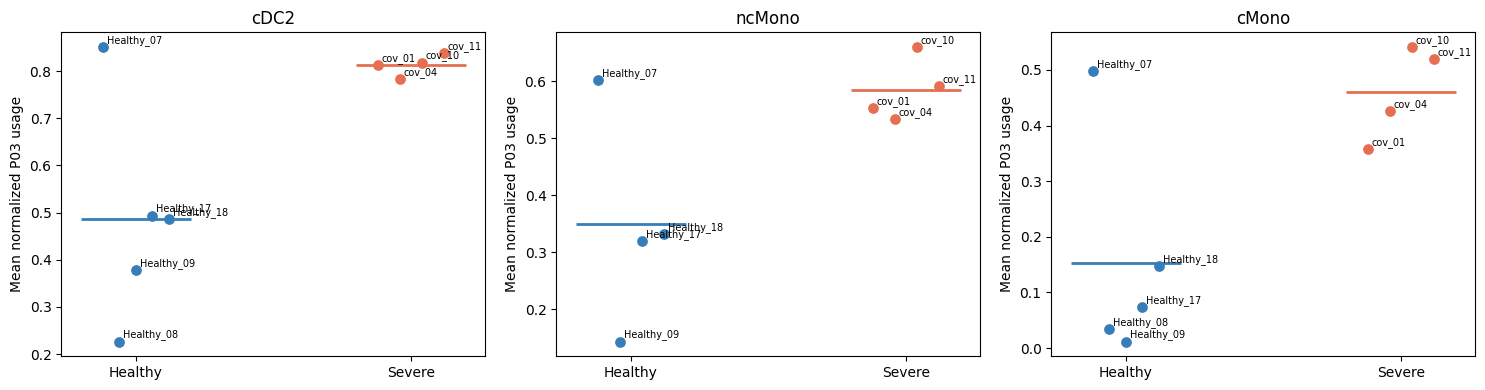

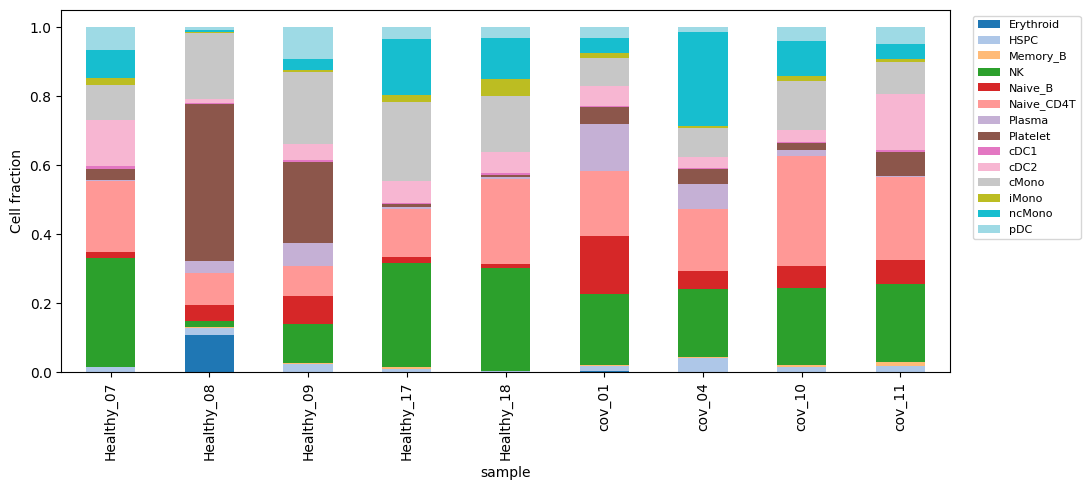

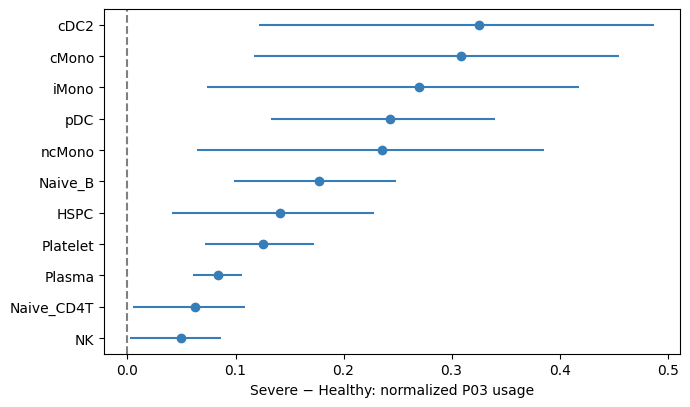

In [39]:
p03_rows = []
for cutoff in sorted(set([P03_MIN_CELLS,30,50])):
    for metric in ['P03_fraction','P03_raw']:
        for ct, frame in p03_summary.groupby(P03_CT,observed=True):
            valid = frame[frame.n_cells>=cutoff]
            result = p03_test(valid.loc[valid[P03_GROUP]==P03_A,metric],
                              valid.loc[valid[P03_GROUP]==P03_B,metric])
            p03_rows.append(dict(cell_type=ct,min_cells=cutoff,metric=metric,**result))
p03_usage_tests = pd.DataFrame(p03_rows)
p03_usage_tests['FDR'] = p03_usage_tests.groupby(['min_cells','metric'])['pvalue'].transform(p03_bh)
p03_usage_tests.to_csv(p03_out/'usage_disease_tests_sensitivity.csv',index=False)
p03_primary = p03_usage_tests[(p03_usage_tests.min_cells==P03_MIN_CELLS)&
                              (p03_usage_tests.metric=='P03_fraction')].copy()
display(p03_primary.sort_values('delta',ascending=False))

fig, axes = plt.subplots(1,len(P03_TARGETS),figsize=(5*len(P03_TARGETS),4),squeeze=False)
for ax,ct in zip(axes.flat,P03_TARGETS):
    frame = p03_summary[(p03_summary[P03_CT]==ct)&(p03_summary.n_cells>=P03_MIN_CELLS)]
    for x,(group,color) in enumerate([(P03_A,'#377eb8'),(P03_B,'#e76f51')]):
        part=frame[frame[P03_GROUP]==group].sort_values(P03_UNIT)
        jitter=np.linspace(-.12,.12,len(part)) if len(part)>1 else np.zeros(len(part))
        ax.scatter(x+jitter,part.P03_fraction,color=color,s=45)
        for xx,(_,row) in zip(x+jitter,part.iterrows()):
            ax.annotate(str(row[P03_UNIT]),(xx,row.P03_fraction),xytext=(3,3),textcoords='offset points',fontsize=7)
        if len(part): ax.hlines(part.P03_fraction.mean(),x-.2,x+.2,color=color,lw=2)
    ax.set(xticks=[0,1],xticklabels=['Healthy','Severe'],title=ct,ylabel='Mean normalized P03 usage')
fig.tight_layout(); fig.savefig(p03_out/'P03_sample_usage.png',dpi=180,bbox_inches='tight'); plt.show()

fig,ax=plt.subplots(figsize=(11,5))
p03_composition.plot.bar(stacked=True,ax=ax,colormap='tab20')
ax.set_ylabel('Cell fraction'); ax.legend(bbox_to_anchor=(1.02,1),fontsize=8)
fig.tight_layout(); fig.savefig(p03_out/'sample_composition.png',dpi=180,bbox_inches='tight'); plt.show()

p03_forest=p03_primary[p03_primary.status=='tested'].sort_values('delta')
if len(p03_forest):
    fig,ax=plt.subplots(figsize=(7,max(3,len(p03_forest)*.38)))
    y=np.arange(len(p03_forest))
    ax.hlines(y,p03_forest.ci_low,p03_forest.ci_high,color='#377eb8')
    ax.scatter(p03_forest.delta,y,color='#377eb8')
    ax.set(yticks=y,yticklabels=p03_forest.cell_type,xlabel='Severe − Healthy: normalized P03 usage')
    ax.axvline(0,color='gray',ls='--'); fig.tight_layout()
    fig.savefig(p03_out/'P03_disease_effects.png',dpi=180,bbox_inches='tight'); plt.show()

### 2. P03 核心 PAC 与候选基因 wPSI（探索性）
使用全部 P03 核心基因，不使用按方向筛选的 leading genes。保留 wPSI 的 0/1，只按非缺失数过滤；非缺失不等于可靠 read 覆盖。
基因的均值仅使用非缺失细胞，因此同时导出有效细胞数。正式 APA 分析应进一步使用原始 PAC 计数、相同可比较位点和覆盖度控制。
所有目标细胞类型 × 基因的有效检验合并做一次 BH 校正；正 ΔwPSI 仅表示数值增加，需核对上游定义才能解释为远端使用增加。

  [P01] 核心基因集大小: 65
  [P02] 核心基因集大小: 66
  [P03] 核心基因集大小: 50
  [P04] 核心基因集大小: 64
  [P05] 核心基因集大小: 33
  [P06] 核心基因集大小: 41
P03核心基因匹配wPSI: 50/50（精确ID匹配）


,cell_type,gene_id,symbol,n_healthy,n_severe,mean_healthy,mean_severe,delta,pvalue,ci_low,ci_high,loo_min,loo_max,loo_same_sign,status,FDR
56,cMono,ENSG00000090382.7,LYZ,5,4,0.935321,0.887564,-0.047757,0.023810,-0.068810,-0.022810,-0.058911,-0.040320,True,tested,0.625000
57,cMono,ENSG00000099860.9,GADD45B,5,4,0.392538,0.295262,-0.097276,0.023810,-0.152230,-0.050368,-0.111458,-0.070410,True,tested,0.625000
44,cDC2,ENSG00000196562.16,SULF2,4,4,0.084172,0.034554,-0.049617,0.028571,-0.084575,-0.017755,-0.058219,-0.034977,True,tested,0.625000
129,ncMono,ENSG00000165312.7,OTUD1,4,4,0.774561,0.693392,-0.081169,0.028571,-0.125081,-0.040854,-0.094897,-0.061275,True,tested,0.625000
30,cDC2,ENSG00000160789.24,LMNA,5,4,0.222022,0.318106,0.096084,0.031746,0.037161,0.149538,0.080050,0.118416,True,tested,0.625000
6,cDC2,ENSG00000090382.7,LYZ,5,4,0.906592,0.865774,-0.040818,0.039683,-0.062707,-0.016440,-0.050487,-0.034094,True,tested,0.625000
42,cDC2,ENSG00000182578.14,CSF1R,5,4,0.702202,0.707146,0.004945,0.039683,0.001095,0.009478,0.003015,0.006228,True,tested,0.625000
91,cMono,ENSG00000182578.14,CSF1R,5,4,0.702037,0.706085,0.004047,0.039683,0.001316,0.007243,0.002788,0.004977,True,tested,0.625000
64,cMono,ENSG00000114013.16,CD86,5,3,0.204181,0.154476,-0.049705,0.053571,-0.079786,-0.019177,-0.061598,-0.039287,True,tested,0.696774
123,ncMono,ENSG00000140105.18,WARS1,4,4,0.123271,0.144641,0.021370,0.057143,0.005302,0.038035,0.014007,0.028326,True,tested,0.696774


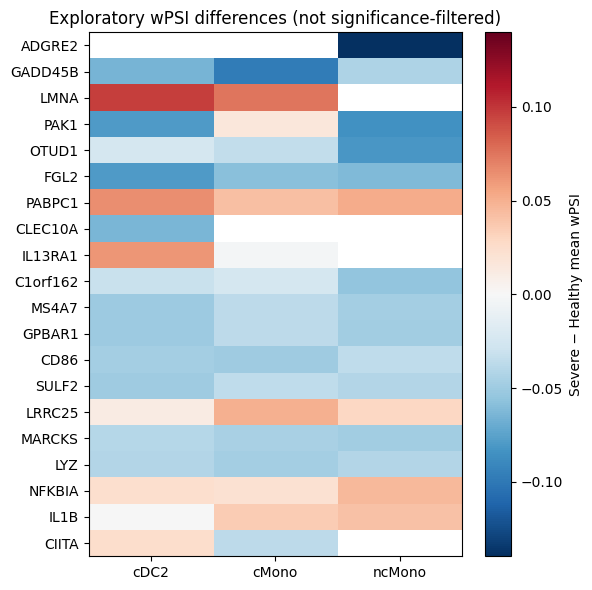

P03分析完成，结果目录: /Users/hedanni/Desktop/DEPA_downstream/outputs/covid_19/p03_disease


In [40]:
from depa_downstream import compute_program_gene_sets
p03_gene_sets = compute_program_gene_sets(data,CONFIG)
p03_core = sorted(p03_gene_sets['gene_sets']['P03'])
p03_map = data.get('gene_symbol_map')
def p03_symbol(gid):
    key=str(gid).split('.')[0]
    return str(p03_map.get(key,gid)) if p03_map is not None else str(gid)
p03_pacs = data['feature_anno'].reindex(data['spectra_z'].columns).copy()
p03_pacs['P03_z'] = data['spectra_z'].loc['P03'].reindex(p03_pacs.index)
p03_pacs['P03_weight'] = data['spectra'].loc['P03'].reindex(p03_pacs.index)
p03_pacs['is_P03_core_PAC'] = p03_pacs.P03_z>CONFIG.get('z_threshold',1.5)
p03_pacs.sort_values('P03_z',ascending=False).to_csv(p03_out/'P03_PAC_annotations.csv')
pd.DataFrame({'gene_id':p03_core,'symbol':[p03_symbol(g) for g in p03_core]}).to_csv(p03_out/'P03_core_genes.csv',index=False)

p03_wpsi_rows=[]
p03_wpsi = data.get('wpsi')
if p03_wpsi is None:
    print('没有加载 wPSI：跳过候选 APA 分析，usage 分析已完成。')
else:
    assert p03_wpsi.index.is_unique and p03_wpsi.columns.is_unique
    p03_genes = pd.Index(p03_core).intersection(p03_wpsi.index)
    print(f'P03核心基因匹配wPSI: {len(p03_genes)}/{len(p03_core)}（精确ID匹配）')
    for (unit,group,ct), frame in p03_cells.groupby(p03_keys,observed=True):
        if ct not in P03_TARGETS or len(frame)<P03_MIN_CELLS: continue
        cell_ids=frame.index.intersection(p03_wpsi.columns)
        block=p03_wpsi.loc[p03_genes,cell_ids].replace([np.inf,-np.inf],np.nan)
        means=block.mean(axis=1); counts=block.notna().sum(axis=1)
        for gid in p03_genes:
            p03_wpsi_rows.append(dict(unit=unit,group=group,cell_type=ct,gene_id=gid,
                symbol=p03_symbol(gid),n_cells=len(frame),n_matrix_cells=len(cell_ids),
                n_valid=int(counts[gid]),valid_fraction=counts[gid]/len(frame),wpsi_mean=means[gid]))
p03_wpsi_samples=pd.DataFrame(p03_wpsi_rows)
p03_gene_tests=pd.DataFrame()
if len(p03_wpsi_samples):
    p03_wpsi_samples.to_csv(p03_out/'P03_gene_sample_wpsi.csv',index=False)
    valid=p03_wpsi_samples[(p03_wpsi_samples.n_valid>=P03_MIN_VALID_WPSI)&
                           (p03_wpsi_samples.valid_fraction>=P03_MIN_VALID_FRAC)]
    rows=[]
    for (ct,gid),frame in valid.groupby(['cell_type','gene_id']):
        result=p03_test(frame.loc[frame.group==P03_A,'wpsi_mean'],frame.loc[frame.group==P03_B,'wpsi_mean'])
        rows.append(dict(cell_type=ct,gene_id=gid,symbol=p03_symbol(gid),**result))
    p03_gene_tests=pd.DataFrame(rows)
    if len(p03_gene_tests):
        p03_gene_tests['FDR']=p03_bh(p03_gene_tests.pvalue)
        p03_gene_tests.to_csv(p03_out/'P03_gene_wpsi_disease_tests.csv',index=False)
        display(p03_gene_tests.sort_values(['FDR','pvalue']).head(30))
        tested=p03_gene_tests[p03_gene_tests.status=='tested'].copy()
        if len(tested):
            top=(tested.assign(abs_delta=tested.delta.abs()).groupby('gene_id').abs_delta.max()
                 .nlargest(20).index)
            heat=tested[tested.gene_id.isin(top)].pivot(index='gene_id',columns='cell_type',values='delta').reindex(top)
            fig,ax=plt.subplots(figsize=(6,max(3,len(heat)*.3)))
            limit=max(.01,float(np.nanmax(np.abs(heat.to_numpy()))))
            im=ax.imshow(np.ma.masked_invalid(heat.to_numpy()),cmap='RdBu_r',vmin=-limit,vmax=limit,aspect='auto')
            ax.set(xticks=np.arange(len(heat.columns)),xticklabels=heat.columns,
                   yticks=np.arange(len(heat)),yticklabels=[p03_symbol(g) for g in heat.index],
                   title='Exploratory wPSI differences (not significance-filtered)')
            fig.colorbar(im,ax=ax,label='Severe − Healthy mean wPSI')
            fig.tight_layout(); fig.savefig(p03_out/'P03_gene_wpsi_effects.png',dpi=180,bbox_inches='tight'); plt.show()
    else: print('没有基因通过有效细胞数过滤。')
else: print('没有可用的样本级 wPSI 记录。')

p03_parameters=dict(program='P03',unit=P03_UNIT,celltype=P03_CT,groups=[P03_A,P03_B],
    min_cells=P03_MIN_CELLS,min_units_per_group=P03_MIN_UNITS,targets=P03_TARGETS,
    min_valid_wpsi=P03_MIN_VALID_WPSI,min_valid_fraction=P03_MIN_VALID_FRAC,seed=P03_SEED,
    usage_primary='row-normalized fraction; sample-equal mean',
    wpsi_method='sample mean of available single-cell wPSI; NOT count-pseudobulk',
    warning='Exploratory; confirm independent donors, batch confounding, PAC coverage and wPSI definition')
(p03_out/'analysis_parameters.json').write_text(json.dumps(p03_parameters,ensure_ascii=False,indent=2))
print('P03分析完成，结果目录:',p03_out)

### 结果阅读顺序
1. `sample_celltype_counts.csv`：确认每组有效样本数量及稀疏细胞类型。
2. `P03_sample_usage.png` / `usage_disease_tests_sensitivity.csv`：看同类细胞内疾病效应、FDR、原始/归一化usage及门槛敏感性。
3. `loo_same_sign`：排查单一样本驱动；不能当作独立验证。
4. `P03_gene_wpsi_disease_tests.csv`：挑选效应稳定、覆盖充分的候选；无显著基因时如实报告。
5. `P03_PAC_annotations.csv`：回到具体位点核对，再用原始PAC计数验证。基因集由同一数据筛选，功能和APA结论都需独立验证。
不要因为未通过FDR就降低阈值追求显著，也不要把正ΔwPSI直接称为UTR延长。